# 03. 실험 비교
담당: Experimentation Lead · 모든 학습 결과(`outputs/experiment_log.jsonl`)를 한 표로 모읍니다.
점수 `map`은 대회 지표와 같은 mAP@[0.75:0.95]입니다 (configs의 eval.iou_thresholds).

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd

from src.utils import load_config
from src.visualize import set_korean_font

set_korean_font()
pd.set_option("display.max_columns", 50)

CONFIG = "configs/base.yaml"  # 샘플 데이터로 연습: "configs/sample_yolo.yaml"
cfg = load_config(CONFIG)
d = cfg["data"]

In [2]:
import json

from src.interfaces import OUTPUT_DIR

rows = [json.loads(line) for line in open(OUTPUT_DIR / "experiment_log.jsonl", encoding="utf-8")]
exp_df = pd.DataFrame(rows).drop_duplicates("exp_name", keep="last")
cols = [
    "exp_name",
    "owner",
    "model",
    "data_version",
    "augment",
    "epochs",
    "img_size",
    "map",
    "map_50",
    "map_75",
    "train_min",
    "note",
]
exp_df[[c for c in cols if c in exp_df]].sort_values("map", ascending=False)

,exp_name,owner,model,data_version,augment,epochs,img_size,map,map_75,train_min,note
0,1028_modelA_yolov8s_v0_baseline,modelA,yolo:yolov8s.pt,v0,none,50,640,0.95340,0.98263,23.08,첫 제출용 베이스라인
1,1028_modelB_frcnn_v0_baseline,modelB,rcnn:fasterrcnn_resnet50_fpn_v2,v0,none,20,640,0.66625,0.74330,91.39,비교용 2단계 탐지기 베이스라인


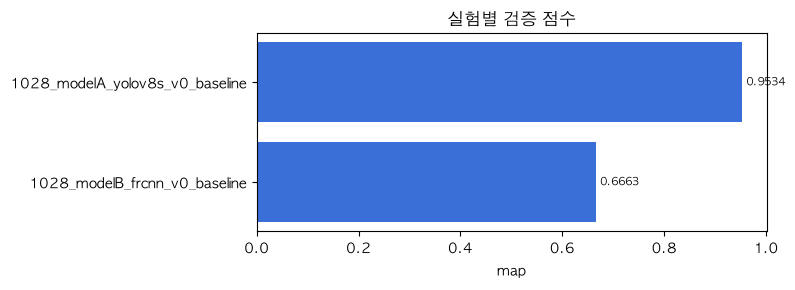

In [3]:
from src.visualize import plot_experiments

plot_experiments(exp_df, metric="map")

## Kaggle 제출 기록
제출한 실험의 Public 점수를 아래 표에 직접 추가합니다 (X 관리).

In [4]:
kaggle = pd.DataFrame(
    [
        # {"exp_name": "1028_modelA_yolov8s_v0_baseline", "kaggle_public": 0.000, "submitted": "10/28"},
    ]
)
exp_df.merge(kaggle, on="exp_name", how="left") if len(kaggle) else exp_df

,exp_name,owner,model,data_version,augment,epochs,img_size,train_min,finished_at,note,map,map_75,map_large,mar_1,mar_10,mar_100,mar_large
0,1028_modelA_yolov8s_v0_baseline,modelA,yolo:yolov8s.pt,v0,none,50,640,23.08,2026-10-23 22:15,첫 제출용 베이스라인,0.95340,0.98263,0.95340,0.96520,0.96520,0.96520,0.96520
1,1028_modelB_frcnn_v0_baseline,modelB,rcnn:fasterrcnn_resnet50_fpn_v2,v0,none,20,640,91.39,2026-10-23 23:52,비교용 2단계 탐지기 베이스라인,0.66625,0.74330,0.66625,0.67907,0.67907,0.67907,0.67907
